In [45]:
import numpy as np
import matplotlib.pyplot as plt

from rowland_geometry.rowland_circle import RowlandCircle
from rowland_geometry.dispersive import DispersiveRefocusing

In [78]:
diameter = 300
bragg = 70
asymmetry = -10
displacement = -100
optic_diameter = 100

Rowland diameter:        300.0 mm
Bragg angle:             70.0000 deg
Asymmetry angle:         -10.0000 deg
Source displacement:     -100.0 mm
Optic diameter:          100.0 mm
Mechanical angle middle: 60.0000 deg
Mechanical angle left:   67.8441 deg
Mechanical angle right:  55.5263 deg


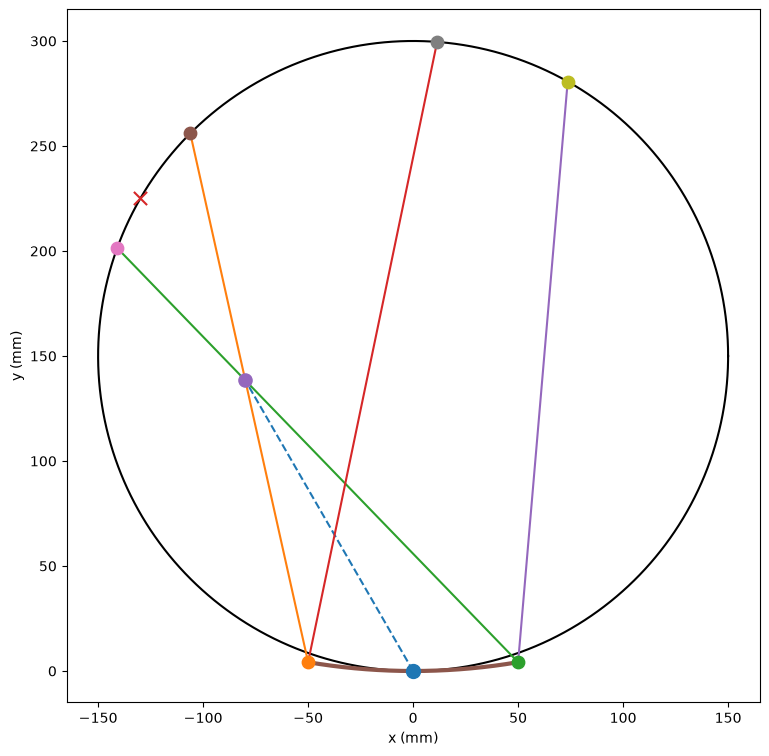

In [79]:
fig, ax = plt.subplots(figsize=(9, 9))

rowland = RowlandCircle(
    diameter=diameter,
    bragg=bragg,
    asymmetry=asymmetry,
)

dispersive = DispersiveRefocusing(
    diameter=diameter,
    bragg=bragg,
    displacement=displacement,
    optic_diameter=optic_diameter,
    asymmetry=asymmetry,
)

# Short names
analyzer = rowland.pos_analyzer
source_on = rowland.pos_source
source_disp = dispersive._pos_displaced_source

left = dispersive._pos_analyzer_left
right = dispersive._pos_analyzer_right

rowland_left = dispersive._pos_rowland_left
rowland_right = dispersive._pos_rowland_right

refocus_left = dispersive._pos_refocus_left
refocus_right = dispersive._pos_refocus_right

# Rowland circle coordinates
radius = rowland.diameter / 2.0
center = rowland.pos_center

phi = np.linspace(0, 2 * np.pi, 500)

x_circle = center[0] + radius * np.cos(phi)
y_circle = center[1] + radius * np.sin(phi)

# Rowland circle
ax.plot(
    x_circle,
    y_circle,
    "k-",
    linewidth=1.5,
    label="Rowland circle",
)

# Rho chord: analyzer center -> displaced source
ax.plot(
    [analyzer[0], source_disp[0]],
    [analyzer[1], source_disp[1]],
    "--",
    linewidth=1.5,
    label=r"$\rho$",
)

# Left analyzer edge -> left incident Rowland-circle intersection
ax.plot(
    [left[0], rowland_left[0]],
    [left[1], rowland_left[1]],
    "-",
    linewidth=1.5,
    label="Left incident ray",
)

# Right analyzer edge -> right incident Rowland-circle intersection
ax.plot(
    [right[0], rowland_right[0]],
    [right[1], rowland_right[1]],
    "-",
    linewidth=1.5,
    label="Right incident ray",
)

# Left analyzer edge -> left refocus point
ax.plot(
    [left[0], refocus_left[0]],
    [left[1], refocus_left[1]],
    "-",
    linewidth=1.5,
    label="Left refocused ray",
)

# Right analyzer edge -> right refocus point
ax.plot(
    [right[0], refocus_right[0]],
    [right[1], refocus_right[1]],
    "-",
    linewidth=1.5,
    label="Right refocused ray",
)

# Analyzer center
ax.scatter(
    analyzer[0],
    analyzer[1],
    s=100,
    zorder=5,
    label="Analyzer center",
)

# Analyzer edges
ax.scatter(
    left[0],
    left[1],
    s=80,
    zorder=5,
    label="Analyzer left",
)

ax.scatter(
    right[0],
    right[1],
    s=80,
    zorder=5,
    label="Analyzer right",
)

# Bent analyzer arc
bending_radius = rowland.diameter
bending_center = np.array([0.0, bending_radius])

theta_left = np.arctan2(
    left[1] - bending_center[1],
    left[0] - bending_center[0],
)

theta_right = np.arctan2(
    right[1] - bending_center[1],
    right[0] - bending_center[0],
)

theta_arc = np.linspace(theta_left, theta_right, 200)

x_analyzer = bending_center[0] + bending_radius * np.cos(theta_arc)
y_analyzer = bending_center[1] + bending_radius * np.sin(theta_arc)

ax.plot(
    x_analyzer,
    y_analyzer,
    linewidth=3.0,
    label="Analyzer surface",
)

# Original on-circle source
ax.scatter(
    source_on[0],
    source_on[1],
    s=90,
    marker="x",
    zorder=5,
    label="On-circle source",
)

# Displaced source
ax.scatter(
    source_disp[0],
    source_disp[1],
    s=90,
    zorder=5,
    label="Displaced source",
)

# Incident-side Rowland-circle intersections
ax.scatter(
    rowland_left[0],
    rowland_left[1],
    s=80,
    zorder=5,
    label="Left Rowland intersection",
)

ax.scatter(
    rowland_right[0],
    rowland_right[1],
    s=80,
    zorder=5,
    label="Right Rowland intersection",
)

# Refocused Rowland-circle points
ax.scatter(
    refocus_left[0],
    refocus_left[1],
    s=80,
    zorder=5,
    label="Left refocus",
)

ax.scatter(
    refocus_right[0],
    refocus_right[1],
    s=80,
    zorder=5,
    label="Right refocus",
)

# Formatting
ax.set_aspect("equal")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
# ax.legend()

theta_m = rowland.bragg + rowland.asymmetry

print(f"Rowland diameter:        {diameter:.1f} mm")
print(f"Bragg angle:             {bragg:.4f} deg")
print(f"Asymmetry angle:         {asymmetry:.4f} deg")
print(f"Source displacement:     {displacement:.1f} mm")
print(f"Optic diameter:          {optic_diameter:.1f} mm")
print(f"Mechanical angle middle: {theta_m:.4f} deg")
print(f"Mechanical angle left:   {dispersive._theta_m_left:.4f} deg")
print(f"Mechanical angle right:  {dispersive._theta_m_right:.4f} deg")

plt.show()